# **SUPERVISED LEARNING**
In this Jupyter Notebook, you will get a hands-on
### **+ LINEAR REGRESSION**
### **+ LOGISTIC REGRESSION**
### **+ SUPPORT VECTOR MACHINE**
### **+ K - NEAREST NEIGHBOURS**

### **1. LINEAR REGRESSION**

**Regression** is a supervised machine-learning task used to predict a numerical value, such as a house price, temperature, or salary.

Simple Linear Regression models the relationship between one input feature and a target:
$$
\hat{y} = b_0 + b_1x
$$

- $(x)$: input feature (for example, house area)
- $\hat{y}$: predicted house price
- $(b_0)$: intercept
- $(b_1)$: slope/coefficient

With multiple input features, the model becomes:

$$
\hat{y} = b_0 + b_1x_1 + b_2x_2 + \cdots + b_nx_n
$$

For example, house price may depend on area, number of bedrooms, age, and location. Linear Regression learns coefficients from the training data to make predictions.

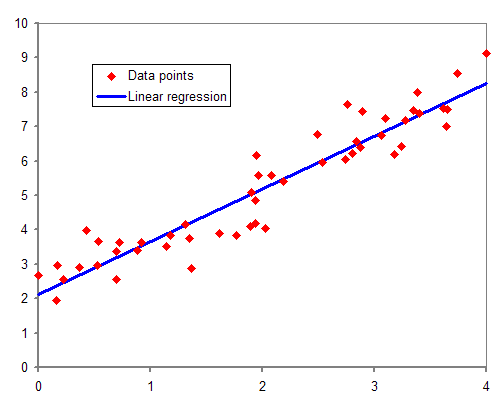

**Key idea:** The model finds a line (or, with multiple features, a hyperplane) that minimizes the sum of squared differences between actual and predicted values.


### 1.1. Import Libraries

In [1]:
%pip install scikit-learn

   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   -- ------------------------------------- 0.5/8.4 MB 2.0 MB/s eta 0:00:04
   ------- -------------------------------- 1.6/8.4 MB 3.5 MB/s eta 0:00:02
   ------------------ --------------------- 3.9/8.4 MB 6.2 MB/s eta 0:00:01
   -------------------------------- ------- 6.8/8.4 MB 8.1 MB/s eta 0:00:01
   ---------------------------------------- 8.4/8.4 MB 8.7 MB/s  0:00:01
   ---------------------------------------- 0.0/37.4 MB ? eta -:--:--
   -- ------------------------------------- 2.1/37.4 MB 11.0 MB/s eta 0:00:04
   ---- ----------------------------------- 4.5/37.4 MB 10.8 MB/s eta 0:00:04
   ------ --------------------------------- 6.0/37.4 MB 11.5 MB/s eta 0:00:03
   ------ --------------------------------- 6.0/37.4 MB 11.5 MB/s eta 0:00:03
   ------- -------------------------------- 6.8/37.4 MB 6.4 MB/s eta 0:00:05
   ---------------- ------

In [ ]:
# Cell 1: Import the libraries we need

import pandas as pd                  # Read and work with tabular data
import numpy as np                   # Numerical operations
import matplotlib.pyplot as plt      # Graphs and visualizations

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Display graphs inside the notebook
%matplotlib inline

print("Libraries imported successfully!")

1.2. Read Dataset

In [ ]:
#https://www.kaggle.com/datasets/saurabhbadole/housing-price-data
df = pd.read_csv('/content/Housing_Price_Data.csv')
print("Dataset shape (rows, columns):", df.shape)
df.head()

Dataset shape (rows, columns): (545, 13)


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


### 1.3. Understand the dataset

Before training a model, inspect the data. Each row usually represents one house, and each column represents a property or its price.

- `shape`: number of rows and columns
- `head()`: first five rows
- `info()`: column names, data types, and non-null counts
- `describe()`: summary statistics for numeric columns


In [ ]:
# Cell 3: Inspect the dataset

print("Dataset dimensions:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst five rows:")
display(df.head())

print("\nData types and missing-value overview:")
df.info()

print("\nSummary of numeric columns:")
display(df.describe())

Dataset dimensions: (545, 13)

Column names:
['price', 'area', 'bedrooms', 'bathrooms', 'stories', 'mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'parking', 'prefarea', 'furnishingstatus']

First five rows:


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished



Data types and missing-value overview:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   price             545 non-null    int64 
 1   area              545 non-null    int64 
 2   bedrooms          545 non-null    int64 
 3   bathrooms         545 non-null    int64 
 4   stories           545 non-null    int64 
 5   mainroad          545 non-null    object
 6   guestroom         545 non-null    object
 7   basement          545 non-null    object
 8   hotwaterheating   545 non-null    object
 9   airconditioning   545 non-null    object
 10  parking           545 non-null    int64 
 11  prefarea          545 non-null    object
 12  furnishingstatus  545 non-null    object
dtypes: int64(6), object(7)
memory usage: 55.5+ KB

Summary of numeric columns:


,price,area,bedrooms,bathrooms,stories,parking
count,5.450000e+02,545.000000,545.000000,545.000000,545.000000,545.000000
mean,4.766729e+06,5150.541284,2.965138,1.286239,1.805505,0.693578
std,1.870440e+06,2170.141023,0.738064,0.502470,0.867492,0.861586
min,1.750000e+06,1650.000000,1.000000,1.000000,1.000000,0.000000
25%,3.430000e+06,3600.000000,2.000000,1.000000,1.000000,0.000000
50%,4.340000e+06,4600.000000,3.000000,1.000000,2.000000,0.000000
75%,5.740000e+06,6360.000000,3.000000,2.000000,2.000000,1.000000
max,1.330000e+07,16200.000000,6.000000,4.000000,4.000000,3.000000


### 1.4. Explore the data with graphs

Graphs help us understand patterns before building a model. The first plot shows the distribution of a numeric column you choose. The second helps inspect relationships between a feature and house price.

**Look for:** unusual values, skewed distributions, and whether larger areas tend to have higher prices. A visible relationship does not automatically prove causation.



Numeric columns: ['price', 'area', 'bedrooms', 'bathrooms', 'stories', 'parking']


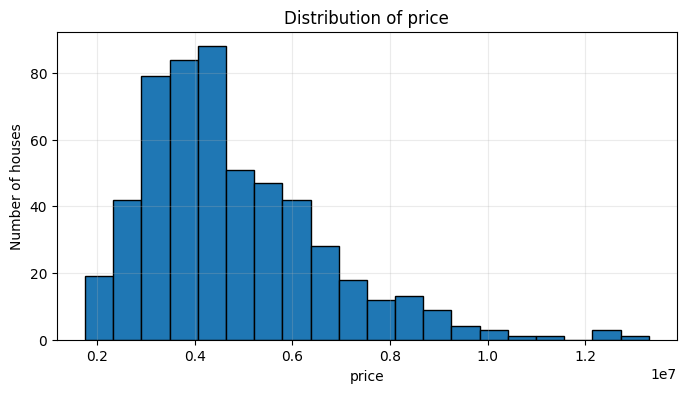

In [ ]:
# Cell 4: Plot a histogram for a numeric column

numeric_columns = df.select_dtypes(include=np.number).columns.tolist()
print("Numeric columns:", numeric_columns)

# Change this to a numeric column in your dataset
column_to_plot = numeric_columns[0]

plt.figure(figsize=(8, 4))
plt.hist(df[column_to_plot].dropna(), bins=20, edgecolor="black")
plt.title(f"Distribution of {column_to_plot}")
plt.xlabel(column_to_plot)
plt.ylabel("Number of houses")
plt.grid(alpha=0.25)
plt.show()

**Scatter plot:**

feature versus price
A scatter plot places one feature on the x-axis and the price on the y-axis. If the points tend to rise from left to right, the feature may have a positive relationship with price.

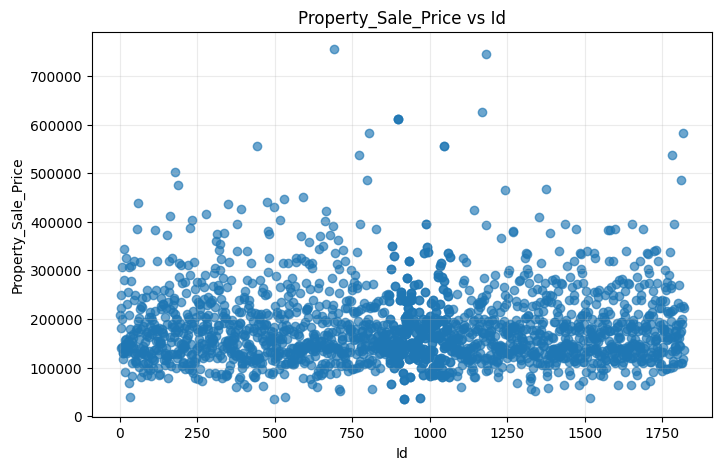

Check that the y-axis is the house-price column before interpreting this graph.


In [ ]:
# Cell 5: Scatter plot — choose the correct column names first

# Replace these examples with the exact names from df.columns
# Example:
# feature_for_plot = "Area"
# target_for_plot = "Price"

feature_for_plot = numeric_columns[0]
target_for_plot = numeric_columns[-1]  # Check that this is actually the price column!

plt.figure(figsize=(8, 5))
plt.scatter(df[feature_for_plot], df[target_for_plot], alpha=0.65)
plt.title(f"{target_for_plot} vs {feature_for_plot}")
plt.xlabel(feature_for_plot)
plt.ylabel(target_for_plot)
plt.grid(alpha=0.25)
plt.show()

print("Check that the y-axis is the house-price column before interpreting this graph.")

In [ ]:
#CODE DEMONSTRATION (FROM DATA LOADING TO MODEL TRAINING)
#LAB PORTION - HOW TO USE MODEL ? ANALYSIS ? GRAPH PLOT UNDERSTANDING ? METRICS ?  QUESTIONS ?
#dataset - Use that property dataset you know

### 1.5. Preprocess the data

Real datasets may contain missing values, duplicate rows, text columns, or currency symbols. We will:
1. Remove duplicate rows.
2. select the target (price) column.
3. select input features.
4. fill missing numeric values with their median.
5. convert categorical columns to numeric using one-hot encoding.

**You must edit `target_column` and `feature_columns` below.** Do not include the target price in `feature_columns`, because that would leak the answer into the inputs.

For a first classroom demonstration, start with numeric features such as area, bedrooms, and house age. The code also supports categorical features such as neighbourhood.


In [ ]:
# Cell 6: Clean duplicate rows and select columns

df = df.drop_duplicates().copy()

# Display the actual column names
print("Available columns:", df.columns.tolist())

# Set the target column (what we want to predict)
target_column = "price"

# Set the input features (what we use to predict price)
feature_columns = ["area", "bedrooms"]

# Validate column names
missing_columns = [
    col for col in [target_column] + feature_columns
    if col not in df.columns
]

if missing_columns:
    print("Error: These columns do not exist:", missing_columns)
else:
    print("Target:", target_column)
    print("Features:", feature_columns)
    display(df[[target_column] + feature_columns].head())

Available columns: ['price', 'area', 'bedrooms', 'bathrooms', 'stories', 'mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'parking', 'prefarea', 'furnishingstatus']
Target: price
Features: ['area', 'bedrooms']


,price,area,bedrooms
0,13300000,7420,4
1,12250000,8960,4
2,12250000,9960,3
3,12215000,7500,4
4,11410000,7420,4


 **Missing values and data types**

For this introductory example, rows with a missing target price are removed because the model needs a known answer during training. Missing input values are filled using the median for numeric columns and the most frequent value for categorical columns.

If your price column contains strings such as `"$250,000"` or `"₹75,00,000"`, clean those strings and convert the column to numeric before proceeding.


In [ ]:
# Cell 7: Prepare X (inputs) and y (target)

from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

# Keep only selected features and target
model_df = df[feature_columns + [target_column]].copy()

# Convert the target to numeric; non-numeric values become NaN
model_df[target_column] = pd.to_numeric(model_df[target_column], errors="coerce")

# Remove rows where the target price is missing or invalid
model_df = model_df.dropna(subset=[target_column])

X = model_df[feature_columns]
y = model_df[target_column]

# Detect numeric and categorical input columns
numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

# Fill missing numeric values with median
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

# Fill missing categories with the most frequent category, then encode them
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Apply the appropriate preprocessing to each column type
preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_transformer, numeric_features),
    ("categorical", categorical_transformer, categorical_features)
])

print("Input shape:", X.shape)
print("Target shape:", y.shape)
print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)
print("Rows available for modelling:", len(model_df))

Input shape: (545, 2)
Target shape: (545,)
Numeric features: ['area', 'bedrooms']
Categorical features: []
Rows available for modelling: 545


### 1.6. Split into training and testing data

We keep some examples aside to test the model on houses it did not train on.

- **Training set:** used to learn the coefficients.
- **Testing set:** used to estimate how well the model predicts unseen examples.

Here, 80% of the data is used for training and 20% for testing. `random_state=42` makes the split reproducible. For a very small dataset, evaluation can be unstable.


In [ ]:
# Cell 8: Train-test split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

print("Training examples:", len(X_train))
print("Testing examples:", len(X_test))

Training examples: 436
Testing examples: 109


### 1.7. Build and train the Linear Regression model

A **pipeline** combines preprocessing and the model so the preprocessing is learned from the training data only. This helps avoid information leakage from the test set.

Calling `fit()` trains the model. Linear Regression estimates coefficients that minimize squared prediction errors on the training set.


In [ ]:
# Cell 9: Create the model pipeline and train it

model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


### 1.8. Make predictions

`predict()` uses the trained model to estimate prices for the test examples. We compare the predicted prices with the actual prices.


In [ ]:
# Cell 10: Predict house prices for the test set

y_pred = model.predict(X_test)

comparison = pd.DataFrame({
    "Actual Price": y_test.to_numpy(),
    "Predicted Price": y_pred,
    "Error (Actual - Predicted)": y_test.to_numpy() - y_pred
})

display(comparison.head(10))

,Actual Price,Predicted Price,Error (Actual - Predicted)
0,4060000,5.721233e+06,-1.661233e+06
1,6650000,5.259090e+06,1.390910e+06
2,3710000,3.605916e+06,1.040843e+05
3,6440000,4.675251e+06,1.764749e+06
4,2800000,4.270456e+06,-1.470456e+06
5,4900000,5.344719e+06,-4.447193e+05
6,5250000,6.045326e+06,-7.953256e+05
7,4543000,5.367037e+06,-8.240375e+05
8,2450000,3.294535e+06,-8.445351e+05
9,3353000,3.780032e+06,-4.270319e+05


### Predict the price of a new house

Create one row with the same feature columns used during training. The names and order of columns must match `feature_columns`.

Edit the example values so they are sensible for your dataset.


In [ ]:
# Cell 11: Predict for a new house — EDIT the example values

# Enter the details of a new house
area = 1500
bedrooms = 3

# Create a DataFrame using the same feature names as the training data
new_house = pd.DataFrame({
    "area": [area],
    "bedrooms": [bedrooms]
})

# Predict the house price
predicted_price = model.predict(new_house)

print("Predicted House Price:", predicted_price[0])

Predicted House Price: 3312961.0050036293


### 1.9. Evaluate the model

Three common regression metrics are:

**1. Mean Absolute Error (MAE)**  
Average absolute difference between actual and predicted values. Lower is better. It uses the same units as the target price.

$
MAE = \frac{1}{n}\sum_{i=1}^{n}|y_i-\hat{y}_i|
$

**2. Mean Squared Error (MSE)**  
Average squared difference. Large errors are penalized more heavily. Lower is better.

$
MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i-\hat{y}_i)^2
$

**3. Root Mean Squared Error (RMSE)**  
Square root of MSE, so it is in the same units as the price. Lower is better.

**4. R² score**  
Measures how much variation the model explains relative to predicting the test-set mean. A score near 1 is strong; 0 is similar to the mean baseline; a negative score means worse than that baseline on the test set.

> Metrics should be interpreted in context. An error of 100,000 may be small or large depending on the currency and typical house price.


In [ ]:
# Cell 12: Calculate regression metrics

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"MAE  : {mae:,.3f}")
print(f"MSE  : {mse:,.3f}")
print(f"RMSE : {rmse:,.3f}")
print(f"R²   : {r2:.3f}")

MAE  : 1,381,158.895
MSE  : 3,280,176,595,474.013
RMSE : 1,811,125.781
R²   : 0.351


### 1.10. Visualize actual vs predicted prices

Each dot represents one test house:
- x-axis: actual price
- y-axis: predicted price
- The dashed diagonal represents perfect predictions.

Dots close to the diagonal indicate more accurate predictions. Dots far away from it indicate larger errors.


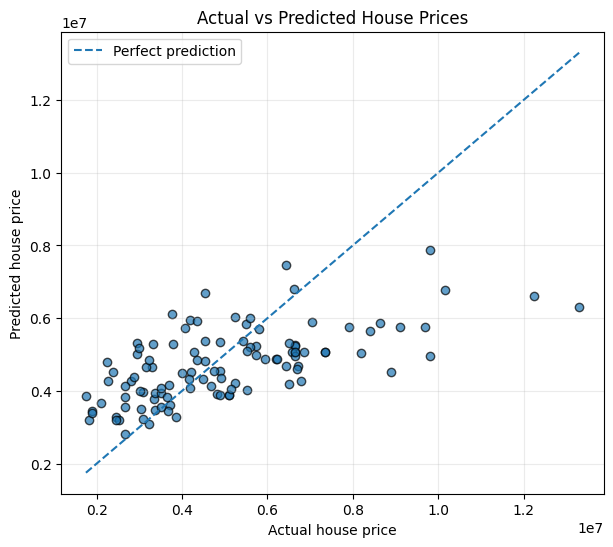

In [ ]:
# Cell 13: Actual vs predicted scatter plot

plt.figure(figsize=(7, 6))
plt.scatter(y_test, y_pred, alpha=0.7, edgecolor="black")

# Reference line from the smallest to largest value
low = min(float(np.min(y_test)), float(np.min(y_pred)))
high = max(float(np.max(y_test)), float(np.max(y_pred)))
plt.plot([low, high], [low, high], linestyle="--", label="Perfect prediction")

plt.xlabel("Actual house price")
plt.ylabel("Predicted house price")
plt.title("Actual vs Predicted House Prices")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

##Question on Linear Regression

1. Print the last 10 rows of the dataset.
2. Count missing values in each column.
3. Find the mean and median of the target price.
4. Change test_size from 0.20 to 0.30. What changes?
5. Train a model using only one feature (for example, area). Compare its metrics with the multi-feature model.
6. Make a bar chart of the top 10 most expensive houses.
7. Print the five test examples with the largest absolute prediction errors.

### **LOGISTIC REGRESSION**


## 2. LOGISTIC REGRESSION

**Logistic Regression** is a supervised machine-learning algorithm used for **classification** problems.

Unlike Linear Regression, which predicts a continuous numerical value, Logistic Regression predicts the probability that an input belongs to a particular class.

For a binary classification problem, there are two possible classes.

Examples:

- Stroke / No Stroke
- Spam / Not Spam
- Pass / Fail
- Disease / No Disease

Logistic Regression first calculates a linear combination of the input features:

$$
z = b_0 + b_1x_1 + b_2x_2 + \cdots + b_nx_n
$$

where:

- $x_1, x_2, \ldots, x_n$ are input features
- $b_0$ is the intercept
- $b_1, b_2, \ldots, b_n$ are the learned coefficients

The value $z$ is then passed through the **sigmoid function**:

$$
\sigma(z) = \frac{1}{1 + e^{-z}}
$$

The sigmoid function converts the output into a value between **0 and 1**, which can be interpreted as a probability.

A threshold is then used to assign a class. For example:

- Probability < 0.5 → Class 0
- Probability ≥ 0.5 → Class 1

In this demonstration, we will use Logistic Regression to predict whether a patient belongs to the **stroke (1)** or **no-stroke (0)** class.

### Visualizing the Sigmoid Function

The **sigmoid function** is the core of Logistic Regression.

It takes any real-valued input and converts it into a value between **0 and 1**.

This output can be interpreted as a probability.

- When the input is very negative, the output is close to **0**
- When the input is **0**, the output is **0.5**
- When the input is very positive, the output is close to **1**

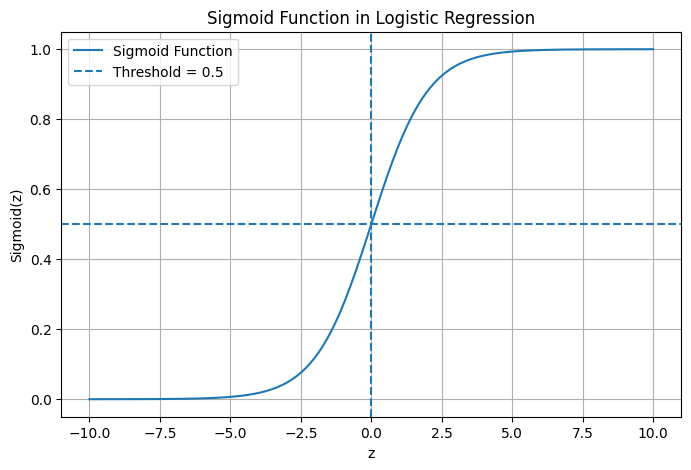

In [ ]:
### 2.1 Import Libraries

import pandas as pd                     # Read and work with tabular data
import numpy as np                      # Numerical operations
import matplotlib.pyplot as plt         # Graphs and visualizations

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

print("Libraries imported successfully!")

Libraries imported successfully!


### 2.2 Read Dataset

The dataset used in this demonstration is the **Stroke Prediction Dataset**.

We will load the CSV file into a Pandas DataFrame using `pd.read_csv()`.

In [ ]:
# Read the dataset
#https://www.kaggle.com/datasets/fedesoriano/stroke-prediction-dataset/data
df = pd.read_csv("/content/sample_data/healthcare-dataset-stroke-data.csv")

print("Dataset shape (rows, columns):", df.shape)

df.head()

Dataset shape (rows, columns): (5110, 12)


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


### 2.3 Understand the Dataset

Before training the model, we should inspect the dataset and understand its structure.

Some useful functions are:

- `shape` : gives the number of rows and columns
- `head()` : displays the first five rows
- `info()` : shows column names, data types, and non-null values
- `isnull().sum()` : shows the number of missing values in each column

In [ ]:
# Display the shape of the dataset
print("Dataset shape:", df.shape)

# Display basic information about the dataset
print("\nDataset information:")
df.info()

# Check missing values
print("\nMissing values in each column:")
print(df.isnull().sum())

Dataset shape: (5110, 12)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   object 
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   object 
 6   work_type          5110 non-null   object 
 7   Residence_type     5110 non-null   object 
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   object 
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), object(5)
memory usage: 479.2+ KB

Missing values in each column:
id                     0
gender                 0
age                    0
hy

In [ ]:
# Display the first 10 rows
df.head(10)

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1
5,56669,Male,81.0,0,0,Yes,Private,Urban,186.21,29.0,formerly smoked,1
6,53882,Male,74.0,1,1,Yes,Private,Rural,70.09,27.4,never smoked,1
7,10434,Female,69.0,0,0,No,Private,Urban,94.39,22.8,never smoked,1
8,27419,Female,59.0,0,0,Yes,Private,Rural,76.15,NaN,Unknown,1
9,60491,Female,78.0,0,0,Yes,Private,Urban,58.57,24.2,Unknown,1


In [ ]:
# Display the last 10 rows
df.tail(10)

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
5100,68398,Male,82.0,1,0,Yes,Self-employed,Rural,71.97,28.3,never smoked,0
5101,36901,Female,45.0,0,0,Yes,Private,Urban,97.95,24.5,Unknown,0
5102,45010,Female,57.0,0,0,Yes,Private,Rural,77.93,21.7,never smoked,0
5103,22127,Female,18.0,0,0,No,Private,Urban,82.85,46.9,Unknown,0
5104,14180,Female,13.0,0,0,No,children,Rural,103.08,18.6,Unknown,0
5105,18234,Female,80.0,1,0,Yes,Private,Urban,83.75,NaN,never smoked,0
5106,44873,Female,81.0,0,0,Yes,Self-employed,Urban,125.20,40.0,never smoked,0
5107,19723,Female,35.0,0,0,Yes,Self-employed,Rural,82.99,30.6,never smoked,0
5108,37544,Male,51.0,0,0,Yes,Private,Rural,166.29,25.6,formerly smoked,0
5109,44679,Female,44.0,0,0,Yes,Govt_job,Urban,85.28,26.2,Unknown,0


### 2.4 Data Preprocessing

Before training the Logistic Regression model, the data must be prepared.

We will perform three simple preprocessing steps:

1. Remove the `id` column because it is only an identifier.
2. Fill the missing values in the `bmi` column using the median.
3. Convert categorical columns into numerical form using one-hot encoding.

In [ ]:
# Remove the id column
df = df.drop("id", axis=1)

# Fill missing bmi values using the median
df["bmi"] = df["bmi"].fillna(df["bmi"].median())

print("Missing values after filling bmi:")
print(df.isnull().sum())

Missing values after filling bmi:
gender               0
age                  0
hypertension         0
heart_disease        0
ever_married         0
work_type            0
Residence_type       0
avg_glucose_level    0
bmi                  0
smoking_status       0
stroke               0
dtype: int64


In [ ]:
# Convert categorical columns into numerical form

df = pd.get_dummies(df, drop_first=True)

print("Dataset shape after encoding:", df.shape)

df.head()

Dataset shape after encoding: (5110, 17)


,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke,gender_Male,gender_Other,ever_married_Yes,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,Residence_type_Urban,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes
0,67.0,0,1,228.69,36.6,1,True,False,True,False,True,False,False,True,True,False,False
1,61.0,0,0,202.21,28.1,1,False,False,True,False,False,True,False,False,False,True,False
2,80.0,0,1,105.92,32.5,1,True,False,True,False,True,False,False,False,False,True,False
3,49.0,0,0,171.23,34.4,1,False,False,True,False,True,False,False,True,False,False,True
4,79.0,1,0,174.12,24.0,1,False,False,True,False,False,True,False,False,False,True,False


**Note:**

- The `id` column is removed because it is only an identifier and does not describe the patient's health.
- Missing values in `bmi` are filled using the median so that the model receives complete numerical data.
- `pd.get_dummies()` converts categorical values such as gender and smoking status into numerical columns.
- `drop_first=True` removes one dummy column from each category to avoid unnecessary duplicate information.

### 2.5 Prepare Features and Target

The dataset must now be divided into:

- **Features (`X`)**: the input variables used by the model
- **Target (`y`)**: the output variable that the model must predict

Here, `stroke` is the target column.

In [ ]:
# Separate input features and target

X = df.drop("stroke", axis=1)
y = df["stroke"]

print("Shape of X:", X.shape)
print("Shape of y:", y.shape)

Shape of X: (5110, 16)
Shape of y: (5110,)


### 2.6 Split the Data into Training and Testing Sets

The dataset is divided into two parts:

- **Training data**: used to train the Logistic Regression model
- **Testing data**: used later to check how well the trained model performs on unseen data

Here, 80% of the data will be used for training and 20% for testing.

In [ ]:
# Split the dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (4088, 16)
X_test shape: (1022, 16)
y_train shape: (4088,)
y_test shape: (1022,)


**Note:**

- `test_size=0.20` means 20% of the data is kept for testing.
- `random_state=42` ensures that the same train-test split is obtained each time the notebook is run.
- `stratify=y` helps maintain approximately the same proportion of stroke and no-stroke cases in both the training and testing sets.

### 2.7 Feature Scaling

Some input features have very different numerical ranges.

For example:

- `age` may range from small values to around 80
- `avg_glucose_level` may have much larger values
- `bmi` follows a different numerical range

To bring the features to a similar scale, we use **StandardScaler**.

In [ ]:
# Create the scaler

scaler = StandardScaler()

# Fit the scaler on the training data and transform it
X_train_scaled = scaler.fit_transform(X_train)

# Apply the same transformation to the testing data
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed.")
print("Scaled training data shape:", X_train_scaled.shape)
print("Scaled testing data shape:", X_test_scaled.shape)

Feature scaling completed.
Scaled training data shape: (4088, 16)
Scaled testing data shape: (1022, 16)


**Note:**

- `fit_transform()` learns the scaling values from the training data and applies the transformation.
- `transform()` applies the same scaling to the testing data.
- The scaler is fitted only on the training data so that information from the test set is not used during model preparation.

### 2.8 Train the Logistic Regression Model

Now that the data has been prepared, we can create and train the Logistic Regression model.

The model learns the relationship between the input features and the target variable `stroke`.

In [ ]:
# Create the Logistic Regression model

model = LogisticRegression(max_iter=100)

# Train the model using the training data

model.fit(X_train_scaled, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


**Note:**

- `LogisticRegression()` creates the classification model.
- `max_iter=100` gives the model enough iterations to complete the training process.
- `model.fit()` trains the model using the training features and their corresponding target values.

# 2.9. LAB PRACTICE - USING AND ANALYSING THE TRAINED MODEL

The Logistic Regression model has now been trained.

In this lab, we will learn how to:

- use the trained model to make predictions,
- compare predictions with actual values,
- evaluate the model using different metrics,
- understand model performance using graphs,
- and use the trained model on unseen data.

## 2.9.1 Making Predictions

After training a model, we can use the `predict()` function to predict the class of new or unseen data.

For our dataset:

- `0` represents **No Stroke**
- `1` represents **Stroke**

Let us first predict the class of a single patient from the test set.

In [ ]:
# Predict the first patient from the test set

single_patient = X_test_scaled[0].reshape(1, -1)

prediction = model.predict(single_patient)

print("Predicted class:", prediction[0])
print("Actual class:", y_test.iloc[0])

Predicted class: 0
Actual class: 0


**Understanding the code:**

- `X_test_scaled[0]` selects the first patient from the test data.
- `reshape(1, -1)` changes it into the format expected by the model.
- `model.predict()` predicts whether the patient belongs to class `0` or class `1`.
- We compare the prediction with the actual value stored in `y_test`.

### Question 1: Predicting Stroke Classes

Use the trained Logistic Regression model to predict the classes for **all patients in the test set**.

Store the predictions in a variable named `y_pred`.

Then:

1. Print the first 10 predicted values.
2. Print the first 10 actual values from `y_test`.
3. Compare them and identify how many of the first 10 predictions are correct.

## 2.9.2 Evaluating the Model Using Accuracy

After making predictions, we need to measure how well the model performs.

One simple evaluation metric is **Accuracy**.

Accuracy tells us the proportion of predictions that were correct.

$$
\text{Accuracy} = \frac{\text{Number of Correct Predictions}}{\text{Total Number of Predictions}}
$$

For example, if a model makes 100 predictions and 90 of them are correct, then the accuracy is:

$$
\frac{90}{100} = 0.90 = 90\%
$$

In [ ]:
# Simple example of accuracy calculation

actual = [0, 1, 0, 1, 1]
predicted = [0, 1, 0, 0, 1]

correct = 4
total = 5

accuracy = correct / total

print("Accuracy:", accuracy)

Accuracy: 0.8


Also, Scikit-learn provides the `accuracy_score()` function to calculate accuracy directly.

In [ ]:
from sklearn.metrics import accuracy_score

example_accuracy = accuracy_score(actual, predicted)

print("Accuracy:", example_accuracy)

Accuracy: 0.8


### Question 2: Calculate Model Accuracy

Using the `y_pred` values obtained in Question 1:

1. Calculate the accuracy of the Logistic Regression model using `accuracy_score()`.
2. Display the accuracy as a decimal value.
3. Convert the accuracy into percentage form.
4. Write one sentence explaining what the obtained accuracy means.

**Note:** A high accuracy does not always mean that a classification model is performing well.

This is especially important when one class occurs much more frequently than the other. Therefore, we will also study other evaluation measures such as the **confusion matrix, precision, recall, and F1-score**.

## 2.9.3 Understanding the Confusion Matrix

A **confusion matrix** shows how many predictions made by the model were correct and how many were incorrect.

For binary classification, it contains four values:

|  | Predicted 0 | Predicted 1 |
|---|---:|---:|
| **Actual 0** | True Negative (TN) | False Positive (FP) |
| **Actual 1** | False Negative (FN) | True Positive (TP) |

For our stroke dataset:

- **True Negative (TN):** No stroke, correctly predicted as no stroke
- **False Positive (FP):** No stroke, incorrectly predicted as stroke
- **False Negative (FN):** Stroke, incorrectly predicted as no stroke
- **True Positive (TP):** Stroke, correctly predicted as stroke

In [ ]:
# Simple example of a confusion matrix

from sklearn.metrics import confusion_matrix

actual = [0, 0, 1, 1, 0, 1]
predicted = [0, 1, 1, 0, 0, 1]

cm = confusion_matrix(actual, predicted)

print(cm)

[[2 1]
 [1 2]]


The output is arranged as:

$$
\begin{bmatrix}
TN & FP \\
FN & TP
\end{bmatrix}
$$

Therefore:

- Top-left value = True Negative
- Top-right value = False Positive
- Bottom-left value = False Negative
- Bottom-right value = True Positive

### Question 3: Confusion Matrix for Stroke Prediction

Using the `y_test` and `y_pred` values from the previous questions:

1. Calculate the confusion matrix for the Logistic Regression model.
2. Print the confusion matrix.
3. Identify the values of:
   - True Negative (TN)
   - False Positive (FP)
   - False Negative (FN)
   - True Positive (TP)
4. Answer the following:

   **Which error is more serious in stroke prediction:**
   
   - predicting stroke for a patient who does not have stroke, or
   - predicting no stroke for a patient who actually has stroke?

   Explain your answer in one or two sentences.

## 2.9.4 Precision, Recall, and F1-Score

Accuracy alone may not give a complete picture of model performance, especially when the classes are imbalanced.

For this reason, we also use **Precision**, **Recall**, and **F1-score**.

### Precision

Precision tells us:

**Out of all the patients predicted as stroke, how many actually had stroke?**

$$
\text{Precision} = \frac{TP}{TP + FP}
$$

### Recall

Recall tells us:

**Out of all the patients who actually had stroke, how many were correctly identified by the model?**

$$
\text{Recall} = \frac{TP}{TP + FN}
$$

### F1-Score

F1-score combines Precision and Recall into a single value.

$$
F1 = 2 \times \frac{\text{Precision} \times \text{Recall}}
{\text{Precision} + \text{Recall}}
$$

In [ ]:
# Simple example of Precision, Recall, and F1-score

from sklearn.metrics import precision_score, recall_score, f1_score

actual = [0, 0, 1, 1, 0, 1]
predicted = [0, 1, 1, 0, 0, 1]

precision = precision_score(actual, predicted)
recall = recall_score(actual, predicted)
f1 = f1_score(actual, predicted)

print("Precision:", precision)
print("Recall:", recall)
print("F1-score:", f1)

Precision: 0.6666666666666666
Recall: 0.6666666666666666
F1-score: 0.6666666666666666


### Question 4: Evaluate the Model Using Precision, Recall, and F1-Score

Using `y_test` and `y_pred`:

1. Calculate the **Precision** of the Logistic Regression model.
2. Calculate the **Recall**.
3. Calculate the **F1-score**.
4. Display all three values.
5. Compare the values and answer:

   **Which metric is most important for this stroke prediction problem? Why?**

## 2.9.5 Classification Report

A **classification report** gives a summary of the main evaluation metrics for each class.

It shows:

- **Precision**
- **Recall**
- **F1-score**
- **Support**

Here, **support** means the number of actual samples belonging to each class.

In [ ]:
from sklearn.metrics import classification_report

actual = [0, 0, 1, 1, 0, 1]
predicted = [0, 1, 1, 0, 0, 1]

print(classification_report(actual, predicted))

              precision    recall  f1-score   support

           0       0.67      0.67      0.67         3
           1       0.67      0.67      0.67         3

    accuracy                           0.67         6
   macro avg       0.67      0.67      0.67         6
weighted avg       0.67      0.67      0.67         6



**How to read the report:**

- Row `0` shows the performance for the **No Stroke** class.
- Row `1` shows the performance for the **Stroke** class.
- `support` shows how many actual samples belong to each class.

### Question 5: Generate the Classification Report

Using `y_test` and `y_pred`:

1. Generate the classification report for the Logistic Regression model.
2. Observe the values for class `0` and class `1`.
3. Compare the recall values of both classes.
4. Answer:

   **Does the model perform equally well for both classes? Explain using the values shown in the report.**

## 2.9.6 Visualizing Actual and Predicted Class Counts

Graphs can help us understand model predictions more easily.

Here, we will compare:

- the number of actual **No Stroke (0)** and **Stroke (1)** cases in the test data,
- the number of cases predicted by the model for each class.

A large difference between the actual and predicted counts may indicate that the model is not predicting one of the classes effectively.

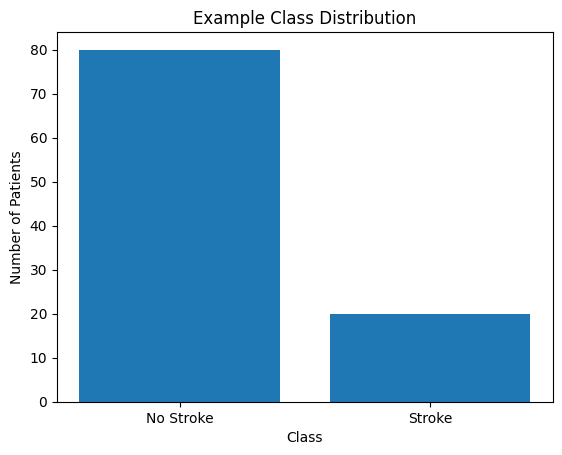

In [ ]:
# Simple example of a bar graph

labels = ["No Stroke", "Stroke"]
counts = [80, 20]

plt.bar(labels, counts)

plt.title("Example Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Patients")

plt.show()

**Understanding the graph:**

- The **x-axis** represents the two classes.
- The **y-axis** represents the number of patients.
- The height of each bar shows how many samples belong to that class.

### Question 6: Compare Actual and Predicted Class Distributions

Using `y_test` and `y_pred`:

1. Count the number of `0` and `1` values in the actual test data.
2. Count the number of `0` and `1` values predicted by the model.
3. Create a bar graph comparing the **Actual** and **Predicted** counts for:
   - No Stroke (0)
   - Stroke (1)
4. Give the graph a suitable title and label both axes.
5. Observe the graph and answer:

   **Does the model predict both classes in approximately the same proportion as the actual test data? Explain your observation.**


Hint:

actual_counts = y_test.value_counts().sort_index()
predicted_counts = pd.Series(y_pred).value_counts().sort_index()

x = np.arange(2)
width = 0.35

Use plt.bar() twice:
one for actual counts, one for predicted counts

## 2.9.7 Using the Trained Model on an Unseen Sample

After training a machine-learning model, we can use it to make predictions on data that the model did not see during training.

Here, we will take one patient from the test set and use the trained Logistic Regression model to predict whether the patient belongs to the:

- **No Stroke (0)** class, or
- **Stroke (1)** class.

In [ ]:
#A small worked example

# Select one unseen patient from the test set

sample = X_test_scaled[5].reshape(1, -1)

# Make prediction

sample_prediction = model.predict(sample)

print("Predicted class:", sample_prediction[0])
print("Actual class:", y_test.iloc[5])

Predicted class: 0
Actual class: 0


**Understanding the output:**

- If the predicted class is `0`, the model predicts **No Stroke**.
- If the predicted class is `1`, the model predicts **Stroke**.
- The predicted class can be compared with the actual class to check whether the prediction is correct.

### Question 7: Test the Trained Model on Unseen Data

Choose any one patient from the test set other than the example shown above.

1. Select the patient from `X_test_scaled`.
2. Use the trained Logistic Regression model to predict the class.
3. Display the predicted class.
4. Display the actual class from `y_test`.
5. State whether the prediction is correct or incorrect.
6. Interpret the predicted class as either:
   - No Stroke
   - Stroke

Hint:

Choose any index from the test set
index = ___

sample = X_test_scaled[index].reshape(1, -1)

prediction = model.predict(__________)

print("Predicted class:", __________)
print("Actual class:", __________)

### **SVM**


# Support Vector Machines (SVM)

**Topic:** Binary classification using the Raisin dataset  
**Goal:** Build an SVM, make a prediction, evaluate it, compare kernels, and interpret a decision-boundary graph.

## The SVM

Imagine drawing a line between red and blue points:
- A **linear SVM** looks for a straight separating line in a two-feature graph (more generally, a *hyperplane*).
- The **margin** is the space between the boundary and its nearest important training points.
- **Support vectors** are the training points that help determine the fitted boundary.
- A **kernel** controls the shape of the boundary. An **RBF** kernel can create a curved boundary; linear, polynomial and sigmoid are other available choices.

**Think–pair–share:** If two groups form curved shapes that cannot be separated by one straight line, would you first try `linear` or `rbf`? Why? (Expected: `rbf`, because a nonlinear boundary may help.)

**Vocabulary to remember:** `fit()` learns from labelled examples; `predict()` assigns labels to inputs not used during training.

## Step 1: Import libraries and load the dataset

This lab uses the same **Raisin classification** problem as the supplied Kaggle example. The **UCI Raisin dataset** contains **900 samples**, **seven measured numerical features**, and **two classes** (`Besni`, `Kecimen`). You do **not** need a Kaggle account for this Colab notebook.

**Source:** [UCI Raisin dataset (ID 850)](https://archive.ics.uci.edu/dataset/850/raisin) · [Original Kaggle reference](https://www.kaggle.com/code/ihsncnkz/classification-with-support-vector-machine-svm) · [CSV mirror used by this notebook](https://github.com/AnanSarah/raisinDataset)

**Attribution:** Çinar, İ., Koklu, M., & Tasdemir, S. (2020), *Raisin*, UCI Machine Learning Repository, DOI: [10.24432/C5660T](https://doi.org/10.24432/C5660T) (CC BY 4.0).

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, ConfusionMatrixDisplay
)

RANDOM_STATE = 42  # same split every time you run the notebook
print("Libraries loaded successfully!")

In [ ]:
# Loads the public CSV directly in Google Colab.
# If internet access to the CSV fails, Colab asks you to upload the CSV manually.
DATA_URL = "https://raw.githubusercontent.com/AnanSarah/raisinDataset/master/Raisin_Dataset.csv"
try:
    df = pd.read_csv(DATA_URL)
    print("Loaded the Raisin CSV online.")
except Exception as error:
    print("Online loading failed:", error)
    print("Download Raisin_Dataset.csv using the mirror link above, then upload it here.")
    from google.colab import files
    import io
    uploaded = files.upload()
    df = pd.read_csv(io.BytesIO(next(iter(uploaded.values()))))

df.columns = df.columns.str.strip()
df["Class"] = df["Class"].astype(str).str.strip()
assert set(df["Class"].unique()) == {"Besni", "Kecimen"}, "Unexpected labels: check CSV"
assert df.shape[1] == 8, "Expected seven input columns and one Class column"

print("Rows, columns:", df.shape)
display(df.head())

In [ ]:
print("Column names:", df.columns.tolist())
print("\nMissing values per column:")
print(df.isna().sum())
print("\nNumber of raisins in each class:")
print(df["Class"].value_counts())

### ✍️ Checkpoint 1 — Understand the dataset (3 marks)

**Q1 (1 mark).** How many rows, numerical input features, and classes are present?  
**Q2 (1 mark).** Which column is the target label? Name **two** input features.  
**Q3 (1 mark).** Is the dataset balanced across classes? Quote the counts shown above.

**Your answer (replace these dots with your own observation):**  

> **Answer:** ...

## Step 2: Make and interpret graphs

The histogram shows whether one measurement differs across the two types of raisins. The scatter plot uses **only two columns**, so overlapping dots do **not** prove the two classes are impossible to distinguish using all seven features.

🔧 **TRY IT:** Run once with `FEATURE_TO_PLOT = "Area"`, then change it to `"MajorAxisLength"` and rerun. Which histogram shows more overlap?

In [ ]:
FEATURE_TO_PLOT = "Area"   # 🔧 TRY IT: change to "MajorAxisLength"

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, color in [("Besni", "tab:blue"), ("Kecimen", "tab:orange")]:
    subset = df[df["Class"] == name]
    axes[0].hist(subset[FEATURE_TO_PLOT], bins=25, alpha=0.55,
                 label=name, color=color)
    axes[1].scatter(subset["MajorAxisLength"], subset["Eccentricity"],
                    s=13, alpha=0.5, label=name, color=color)
axes[0].set(title=f"Distribution of {FEATURE_TO_PLOT}", xlabel=FEATURE_TO_PLOT,
            ylabel="Number of raisins")
axes[1].set(title="Two-feature scatter plot", xlabel="MajorAxisLength",
            ylabel="Eccentricity")
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.show()

**Discuss (ungraded):** What does overlap between the blue and orange points mean for classification? Your interpretation should refer to the *two displayed measurements*, not the whole seven-feature dataset.

## Step 3: Split, scale, train, predict

- **`X` (features):** the seven measurement columns used as inputs.
- **`y` (target):** the class name we want to predict.
- **Training set:** data used to learn the pattern.
- **Test set:** data held aside for a final performance check.
- **Scaling:** makes features with different numerical ranges more comparable for SVM.

We use a `Pipeline`: it fits `StandardScaler` **only on training data**, then applies the correct transformation automatically when predicting. This prevents *data leakage* from the held-out test set.

Keep the provided random seed and 80/20 split so everyone can compare results.

In [ ]:
X = df.drop(columns=["Class"])
y = df["Class"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
print("Training rows:", len(X_train), "| Test rows:", len(X_test))
print("Features used:", X.columns.tolist())

In [ ]:
# Our first classifier: LINEAR SVM, with scaling inside the pipeline.
model = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(kernel="linear", C=1.0))
])

model.fit(X_train, y_train)       # LEARN from training examples
y_pred = model.predict(X_test)    # PREDICT labels on unseen test examples
print("First 5 predictions:", y_pred[:5])

In [ ]:
# Practical use: ask the trained model to classify ONE test-set example.
# Double brackets keep the same DataFrame column names and 2D shape.
one_raisin = X_test.iloc[[0]]
print("Measurements for one raisin:")
display(one_raisin)
print("Model prediction:", model.predict(one_raisin)[0])
print("Actual label:", y_test.iloc[0])

# Later, external raisins can be predicted if their seven feature measurements
# are available in the SAME column order and measurement units as the training data.

### ✍️ Checkpoint 2 — Explain how the model works (4 marks)

**Q4 (1 mark).** How many training and test rows were created?  
**Q5 (1 mark).** What is the difference between `fit()` and `predict()`?  
**Q6 (1 mark).** What did the model predict for the one displayed example? Was it correct?  
**Q7 (1 mark).** Why is `StandardScaler()` placed inside a `Pipeline` instead of fitting the scaler on the full dataset before splitting?

**Your answer (replace these dots with your own observation):**  

> **Answer:** ...

## Step 4: Read model-evaluation metrics

The model can be wrong, so a prediction must be evaluated against the true test labels.

| Metric | Beginner meaning |
|---|---|
| **Accuracy** | Of **all** test predictions, what fraction was correct? |
| **Precision (Kecimen)** | Of predictions labelled *Kecimen*, how many really were *Kecimen*? |
| **Recall (Kecimen)** | Of actual *Kecimen* raisins, how many did we find? |
| **F1-score (Kecimen)** | A balance of precision and recall. |

**Confusion matrix:** **Rows = actual class**, **columns = predicted class**. Values on the main diagonal are correctly classified. Off-diagonal entries are mistakes.

In [ ]:
print(f"Accuracy:           {accuracy_score(y_test, y_pred):.3f}")
print(f"Kecimen precision:  {precision_score(y_test, y_pred, pos_label='Kecimen'):.3f}")
print(f"Kecimen recall:     {recall_score(y_test, y_pred, pos_label='Kecimen'):.3f}")
print(f"Kecimen F1-score:   {f1_score(y_test, y_pred, pos_label='Kecimen'):.3f}")
print("\nPerformance report for BOTH classes:")
print(classification_report(y_test, y_pred, digits=3))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, labels=["Besni", "Kecimen"], cmap="Blues", values_format="d"
)
plt.title("Linear SVM: actual vs predicted")
plt.show()

### ✍️ Checkpoint 3 — Analyze the output (5 marks)

**Q8 (1 mark).** Record the test accuracy, rounded to **three decimal places**.  
**Q9 (1 mark).** In the matrix, what do the **diagonal** numbers represent?  
**Q10 (1 mark).** How many **actual Besni** raisins were predicted as **Kecimen**? State the row and column you read.  
**Q11 (1 mark).** What is the difference between precision and recall for Kecimen?  
**Q12 (1 mark).** Why does testing on held-out data tell us more about real predictions than reporting training accuracy alone?

**Your answer (replace these dots with your own observation):**  

> **Answer:** ...

## Step 5: Compare SVM kernels

So far our SVM used `kernel="linear"`. Let's compare four options **fairly** using only the training set:

| Kernel | Boundary idea |
|---|---|
| `linear` | Straight boundary in a 2-feature plane |
| `poly` | Polynomial-shaped separation |
| `rbf` | Flexible nonlinear separation |
| `sigmoid` | A different nonlinear similarity function |

**Three-fold cross-validation (CV):** The training data are divided into three parts. The model trains on two parts and is checked on the third, repeating three times. We average the **validation** accuracies. The held-out test data are **not used to choose a kernel**.

🔧 **TRY IT:** First run all four kernels. Then edit `KERNELS_TO_COMPARE` to remove one kernel and rerun. What changes in the table? Restore all four before submitting.

In [ ]:
KERNELS_TO_COMPARE = ["linear", "poly", "rbf", "sigmoid"]   # 🔧 TRY IT
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
rows = []
for name in KERNELS_TO_COMPARE:
    candidate = Pipeline([
        ("scaler", StandardScaler()),
        ("svm", SVC(kernel=name, C=1.0, gamma="scale"))
    ])
    # This compares the models using training data ONLY.
    cv_scores = cross_val_score(candidate, X_train, y_train,
                                cv=cv, scoring="accuracy")
    rows.append({"Kernel": name, "Average CV accuracy": cv_scores.mean()})

results = pd.DataFrame(rows).sort_values(
    "Average CV accuracy", ascending=False
).reset_index(drop=True)
display(results.round(3))

plt.figure(figsize=(7, 3.5))
plt.bar(results["Kernel"], results["Average CV accuracy"], color="steelblue")
plt.ylim(0, 1)
plt.xlabel("Kernel")
plt.ylabel("Average validation accuracy")
plt.title("Comparing kernels (3-fold training CV)")
plt.show()

best_kernel = results.loc[0, "Kernel"]
print("Highest CV accuracy in this experiment:", best_kernel)

In [ ]:
# Fit the selected kernel on ALL training rows, then evaluate on the untouched test set.
selected_model = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(kernel=best_kernel, C=1.0, gamma="scale"))
])
selected_model.fit(X_train, y_train)
selected_test_accuracy = accuracy_score(y_test, selected_model.predict(X_test))
print("CV-selected kernel:", best_kernel)
print(f"Its HELD-OUT TEST accuracy: {selected_test_accuracy:.3f}")
print("Note: do not repeatedly select kernels based on this test result.")

### ✍️ Checkpoint 4 — Kernel experiment (5 marks)

**Q13 (2 marks).** List **all four kernels** with their average CV accuracies (round to 3 decimals).  
**Q14 (1 mark).** Which kernel scored highest according to your CV table?  
**Q15 (1 mark).** Did this notebook compare the kernels using the training data or the test data?  
**Q16 (1 mark).** Does a more complex kernel *always* beat a linear one? Use your table to support your answer.

**Your answer (replace these dots with your own observation):**  

> **Answer:** ...

## Step 6: Visualize the decision boundary

To display a decision boundary, we need **two dimensions**. Therefore the graph below trains **two new demonstration models using only `MajorAxisLength` and `Eccentricity`**. It is **not** a plot of the all-seven-feature classifier evaluated above.

- **Background shading:** which class the model would predict in that region.
- **Dots:** actual training raisins (orange and blue).
- **Black outline circles:** support vectors.
- **Black dividing line:** model's decision boundary.

🔧 **TRY IT:** Compare the shapes of the `linear` and `rbf` boundaries. A curve is **not automatically more accurate**; the shape must suit the data.

In [ ]:
plot_features = ["MajorAxisLength", "Eccentricity"]
X_plot = X_train[plot_features]
class_code = {"Besni": 0, "Kecimen": 1}

# A mesh of possible 2D measurements that we classify to paint the background.
x_min, x_max = X_plot.iloc[:, 0].min(), X_plot.iloc[:, 0].max()
y_min, y_max = X_plot.iloc[:, 1].min(), X_plot.iloc[:, 1].max()
x_pad, y_pad = (x_max - x_min) * 0.07, (y_max - y_min) * 0.07
xx, yy = np.meshgrid(
    np.linspace(x_min - x_pad, x_max + x_pad, 110),
    np.linspace(y_min - y_pad, y_max + y_pad, 110)
)
mesh_input = pd.DataFrame({plot_features[0]: xx.ravel(),
                           plot_features[1]: yy.ravel()})

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
for ax, kernel in zip(axes, ["linear", "rbf"]):
    demo = Pipeline([
        ("scaler", StandardScaler()),
        ("svm", SVC(kernel=kernel, C=1.0))
    ])
    demo.fit(X_plot, y_train)
    background = pd.Series(demo.predict(mesh_input)).map(class_code).to_numpy()
    ax.contourf(xx, yy, background.reshape(xx.shape),
                levels=[-0.5, 0.5, 1.5], cmap="coolwarm", alpha=0.23)
    ax.contour(xx, yy, demo.decision_function(mesh_input).reshape(xx.shape),
               levels=[0], colors="black", linewidths=1.4)
    for name, color in [("Besni", "tab:blue"), ("Kecimen", "tab:orange")]:
        sub = X_plot[y_train == name]
        ax.scatter(sub.iloc[:, 0], sub.iloc[:, 1], s=12, alpha=0.5,
                   color=color, label=name)
    # SVC.support_ indexes rows by position in the fitted training matrix.
    supports = X_plot.iloc[demo.named_steps["svm"].support_]
    ax.scatter(supports.iloc[:, 0], supports.iloc[:, 1], s=43,
               facecolors="none", edgecolors="black", linewidths=0.6)
    ax.set(title=f"{kernel.upper()} SVM — TWO features only",
           xlabel=plot_features[0], ylabel=plot_features[1])
    ax.legend(loc="best", fontsize=8)
plt.show()

### ✍️ Checkpoint 5 — Explain the plots (3 marks)

**Q17 (1 mark).** Which plot has a straight boundary? Which can have a curved boundary?  
**Q18 (1 mark).** What do the black-outlined support-vector points represent?  
**Q19 (1 mark).** Why is this two-feature plot **not** the decision boundary of the main model trained using seven features?

**Your answer (replace these dots with your own observation):**  

> **Answer:** ...

### **KNN**


Definition:
KNN is a Supervised Learning algorithm used for both classification and regression. It assumes that similar things exist in close proximity.

​How it Works (The Algorithm):
​Load the data.
​Choose the number of neighbors, K (usually an odd number to avoid ties).
​For a new data point, calculate the distance (e.g., Euclidean distance) between this new point and all other points in the training dataset.
​Find the K closest points (the "nearest neighbors").
​Vote: Assign the new point to the class that is most common among its K neighbors.

In [ ]:
# 1. IMPORTING NECESSARY LIBRARIES
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Ensure plots show up in the notebook
%matplotlib inline

​Phase 1: Data Loading & Exploration
​Note: Please upload the train.csv file from the Kaggle Mobile Price Classification dataset to your Colab environment before running the next cell.

In [ ]:
# Load the dataset
# Dataset link: https://www.kaggle.com/datasets/iabhishekofficial/mobile-price-classification
df = pd.read_csv('train.csv')

# Look at the first 5 rows
display(df.head())

# Check the distribution of our target variable (price_range)
print("\nTarget Variable Distribution:")
print(df['price_range'].value_counts())

Phase 2: Data Preprocessing

​Before training KNN, we must prepare our data.
​Why do we need Feature Scaling?
KNN relies on calculating distances (like drawing a straight line with a ruler between two points). If one feature has a range of 1 to 10 (like hours of talk time) and another has a range of 500 to 4000 (like battery power), the distance calculation will be completely dominated by the battery power!
​We use StandardScaler to shrink/expand all features so they have a mean of 0 and a standard deviation of 1.

In [ ]:
# 1. Separate Features (X) and Target (y)
X = df.drop('price_range', axis=1)
y = df['price_range']

# 2. Train-Test Split (80% for training, 20% for testing)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Feature Scaling (CRITICAL FOR KNN)
scaler = StandardScaler()

# Fit on training data and transform both train and test data
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Data successfully scaled!")

Phase 3: Model Training

​
Now we will build the actual KNN model. We will start by picking a random value for K, let's say k=5.

In [ ]:
# Initialize the model with K=5
knn_model = KNeighborsClassifier(n_neighbors=5)

# Train (fit) the model using our scaled training data
knn_model.fit(X_train_scaled, y_train)

print("Model training complete.")

Phase 4: LAB PORTION - Usage, Analysis & Graph Plotting

​Now that our model is trained, how do we use it? We pass our X_test data into the model to make predictions, and then compare those predictions against the actual y_test answers to see how accurate we are.

In [ ]:
# 1. HOW TO USE THE MODEL (Making Predictions)
predictions = knn_model.predict(X_test_scaled)

# 2. ANALYSIS (Accuracy and Confusion Matrix)
accuracy = accuracy_score(y_test, predictions)
print(f"Model Accuracy with K=5: {accuracy * 100:.2f}%\n")

print("Classification Report:")
print(classification_report(y_test, predictions))

# Plotting the Confusion Matrix
plt.figure(figsize=(6,4))
sns.heatmap(confusion_matrix(y_test, predictions), annot=True, cmap='Blues', fmt='d')
plt.title('Confusion Matrix (K=5)')
plt.xlabel('Predicted Price Range')
plt.ylabel('Actual Price Range')
plt.show()

Graph Plot Understanding: The "Elbow Method"

​We guessed K=5 above, but is 5 the best number of neighbors?
​To find the optimal K, we can run a loop, training a new KNN model for every K from 1 to 20. We will record the error rate for each model and plot it. The point where the error rate is at its lowest (and stabilizes) is our optimal K!

In [ ]:
error_rate = []

# Will take some time depending on your computer
for i in range(1, 21):
    knn = KNeighborsClassifier(n_neighbors=i)
    knn.fit(X_train_scaled, y_train)
    pred_i = knn.predict(X_test_scaled)
    # Average where predictions do NOT equal the actual labels
    error_rate.append(np.mean(pred_i != y_test))

# Plotting the Error Rate vs K Value
plt.figure(figsize=(10,6))
plt.plot(range(1, 21), error_rate, color='blue', linestyle='dashed', marker='o',
         markerfacecolor='red', markersize=8)
plt.title('Error Rate vs. K Value')
plt.xlabel('K (Number of Neighbors)')
plt.ylabel('Error Rate')
plt.xticks(range(1, 21))
plt.grid(True)
plt.show()

Practice Questions

​1. The Overfitting Trap: What happens to the testing accuracy if you change the code in Phase 3 to n_neighbors=1? Why? (Hint: Is the model learning rules, or just memorizing the exact points in the training set?)

​2. Missing the Scaling: Create a new model called knn_unscaled. Train and predict using X_train and X_test (the raw, unscaled data). How big is the drop in accuracy?

​3. Changing the Math: Read the KNeighborsClassifier documentation and change the parameter p=2 to p=1 in Phase 3. This forces the model to use the Manhattan Distance instead of Euclidean. Does the accuracy go up or down?

​4. Graph Analysis: Run the Elbow Method graph. Based on the visualization, what exact K value would you recommend for the final model deployment?